## 1. Import library dan membaca dataset

In [1]:
# Import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Membaca dataset
df = pd.read_csv('03_counter_strike_2.csv')

# Menampilkan 5 data pertama
df.head()

# TAQIYA RIZKIPUDENTA_202431180

,time_left,ct_score,t_score,map,bomb_planted,ct_health,t_health,ct_armor,t_armor,ct_money,t_money,ct_helmets,t_helmets,round_winner
0,175.00,0.0,0.0,de_dust2,False,500.0,500.0,0.0,0.0,4000.0,4000.0,0.0,0.0,CT
1,156.03,0.0,0.0,de_dust2,False,500.0,500.0,400.0,300.0,600.0,650.0,0.0,0.0,CT
2,96.03,0.0,0.0,de_dust2,False,391.0,400.0,294.0,200.0,750.0,500.0,0.0,0.0,CT
3,76.03,0.0,0.0,de_dust2,False,391.0,400.0,294.0,200.0,750.0,500.0,0.0,0.0,CT
4,174.97,1.0,0.0,de_dust2,False,500.0,500.0,192.0,0.0,18350.0,10750.0,0.0,0.0,CT


## 2. Exploratory Data Analysis (EDA)

Ukuran dataset: (2000, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   time_left     2000 non-null   float64
 1   ct_score      2000 non-null   float64
 2   t_score       2000 non-null   float64
 3   map           2000 non-null   object 
 4   bomb_planted  2000 non-null   bool   
 5   ct_health     2000 non-null   float64
 6   t_health      2000 non-null   float64
 7   ct_armor      2000 non-null   float64
 8   t_armor       2000 non-null   float64
 9   ct_money      2000 non-null   float64
 10  t_money       2000 non-null   float64
 11  ct_helmets    2000 non-null   float64
 12  t_helmets     2000 non-null   float64
 13  round_winner  2000 non-null   object 
dtypes: bool(1), float64(11), object(2)
memory usage: 205.2+ KB

Missing Values:
time_left       0
ct_score        0
t_score         0
map             0
bomb_planted    0
ct_heal

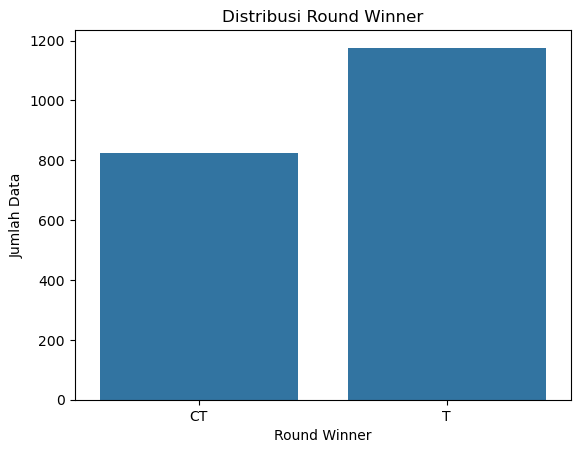

In [2]:
# Menampilkan ukuran dataset
print("Ukuran dataset:", df.shape)

# Menampilkan informasi dataset
df.info()

# Mengecek missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Mengecek data duplikat
print("\nJumlah data duplikat:", df.duplicated().sum())

# Melihat distribusi target
print("\nDistribusi round_winner:")
print(df['round_winner'].value_counts())

# Visualisasi distribusi target
sns.countplot(data=df, x='round_winner')
plt.title('Distribusi Round Winner')
plt.xlabel('Round Winner')
plt.ylabel('Jumlah Data')
plt.show()

# TAQIYA RIZKIPUDENTA_202431180

## 3. Preprocessing data

In [3]:
# Menghapus data duplikat
df = df.drop_duplicates()

# Menghapus baris yang memiliki missing values
df = df.dropna()

# Memisahkan fitur dan target
X = df.drop('round_winner', axis=1)
y = df['round_winner']

# Mengubah fitur kategorikal menjadi numerik
X = pd.get_dummies(X, drop_first=False)

# Membagi dataset menjadi data training dan testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Normalisasi fitur menggunakan StandardScaler
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Jumlah data training:", X_train.shape[0])
print("Jumlah data testing:", X_test.shape[0])
print("Jumlah fitur setelah encoding:", X_train.shape[1])

# TAQIYA RIZKIPUDENTA_202431180

Jumlah data training: 1568
Jumlah data testing: 393
Jumlah fitur setelah encoding: 19


## 4. Implementasi algoritma Naive Bayes

In [4]:
# Membuat model Naive Bayes
model_nb = GaussianNB()

# Melatih model
model_nb.fit(X_train_scaled, y_train)

# Melakukan prediksi
y_pred_nb = model_nb.predict(X_test_scaled)

# Menampilkan hasil prediksi
print("Hasil Prediksi Naive Bayes:")
print(y_pred_nb)

# TAQIYA RIZKIPUDENTA_202431180

Hasil Prediksi Naive Bayes:
['CT' 'T' 'T' 'T' 'T' 'T' 'CT' 'CT' 'T' 'T' 'T' 'CT' 'T' 'CT' 'T' 'CT'
 'CT' 'CT' 'T' 'CT' 'CT' 'T' 'T' 'T' 'T' 'CT' 'CT' 'CT' 'CT' 'T' 'CT' 'T'
 'CT' 'T' 'CT' 'T' 'T' 'CT' 'T' 'CT' 'CT' 'T' 'CT' 'T' 'T' 'T' 'CT' 'T'
 'T' 'T' 'CT' 'CT' 'T' 'T' 'CT' 'T' 'T' 'T' 'T' 'T' 'T' 'T' 'T' 'CT' 'T'
 'T' 'CT' 'T' 'CT' 'CT' 'T' 'CT' 'T' 'T' 'T' 'T' 'T' 'CT' 'CT' 'CT' 'CT'
 'CT' 'T' 'CT' 'CT' 'T' 'T' 'CT' 'T' 'T' 'T' 'T' 'CT' 'CT' 'T' 'CT' 'T'
 'T' 'T' 'T' 'CT' 'CT' 'T' 'T' 'T' 'CT' 'T' 'T' 'CT' 'T' 'T' 'CT' 'T' 'T'
 'T' 'T' 'CT' 'CT' 'T' 'T' 'T' 'CT' 'T' 'T' 'CT' 'T' 'CT' 'CT' 'CT' 'CT'
 'T' 'CT' 'CT' 'T' 'CT' 'T' 'T' 'T' 'CT' 'T' 'T' 'T' 'CT' 'CT' 'T' 'CT'
 'T' 'CT' 'CT' 'T' 'CT' 'T' 'T' 'CT' 'T' 'CT' 'T' 'CT' 'T' 'T' 'T' 'CT'
 'T' 'T' 'T' 'CT' 'T' 'T' 'CT' 'T' 'T' 'T' 'CT' 'T' 'CT' 'CT' 'T' 'T' 'T'
 'T' 'T' 'CT' 'CT' 'T' 'CT' 'T' 'T' 'T' 'T' 'T' 'T' 'T' 'T' 'T' 'CT' 'T'
 'T' 'T' 'T' 'T' 'T' 'T' 'T' 'CT' 'T' 'T' 'CT' 'T' 'CT' 'CT' 'T' 'T' 'T'
 'CT' 'CT' 'T' 'T' 'CT' 'T

## 5. Implementasi algoritma K-Nearest Neighbor (KNN)

In [5]:
# Membuat model KNN dengan k = 5
model_knn = KNeighborsClassifier(n_neighbors=5)

# Melatih model
model_knn.fit(X_train_scaled, y_train)

# Melakukan prediksi
y_pred_knn = model_knn.predict(X_test_scaled)

# Menampilkan hasil prediksi
print("Hasil Prediksi KNN:")
print(y_pred_knn)

# TAQIYA RIZKIPUDENTA_202431180

Hasil Prediksi KNN:
['CT' 'CT' 'T' 'T' 'T' 'CT' 'CT' 'T' 'T' 'T' 'T' 'T' 'CT' 'CT' 'T' 'T' 'T'
 'CT' 'T' 'T' 'CT' 'T' 'T' 'T' 'T' 'T' 'CT' 'CT' 'CT' 'T' 'CT' 'CT' 'CT'
 'T' 'T' 'T' 'T' 'CT' 'CT' 'T' 'CT' 'T' 'CT' 'CT' 'T' 'T' 'CT' 'T' 'T'
 'CT' 'CT' 'T' 'T' 'T' 'CT' 'T' 'T' 'T' 'T' 'T' 'CT' 'CT' 'T' 'CT' 'T' 'T'
 'T' 'T' 'CT' 'CT' 'T' 'T' 'T' 'T' 'T' 'T' 'CT' 'CT' 'T' 'CT' 'T' 'T' 'T'
 'T' 'CT' 'CT' 'T' 'CT' 'T' 'CT' 'T' 'CT' 'CT' 'T' 'T' 'T' 'CT' 'T' 'T'
 'T' 'T' 'CT' 'T' 'CT' 'CT' 'CT' 'T' 'T' 'CT' 'T' 'T' 'CT' 'CT' 'T' 'T'
 'CT' 'CT' 'T' 'T' 'T' 'T' 'CT' 'T' 'T' 'T' 'T' 'CT' 'T' 'CT' 'T' 'T' 'T'
 'T' 'T' 'CT' 'CT' 'CT' 'T' 'T' 'T' 'T' 'T' 'CT' 'T' 'T' 'CT' 'T' 'CT'
 'CT' 'T' 'CT' 'CT' 'T' 'CT' 'T' 'CT' 'T' 'T' 'T' 'T' 'T' 'T' 'T' 'T' 'CT'
 'CT' 'CT' 'T' 'CT' 'T' 'T' 'T' 'CT' 'CT' 'CT' 'CT' 'T' 'T' 'T' 'T' 'T'
 'CT' 'CT' 'T' 'T' 'CT' 'T' 'CT' 'T' 'CT' 'T' 'CT' 'T' 'T' 'CT' 'T' 'CT'
 'T' 'CT' 'T' 'T' 'T' 'T' 'CT' 'T' 'T' 'CT' 'T' 'CT' 'CT' 'T' 'CT' 'T' 'T'
 'CT' 'T' 'CT' 'CT' 'T' 'T' 

## 6. Evaluasi model

In [6]:
# Fungsi evaluasi model
def evaluasi_model(y_test, y_pred, nama_model):
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred,
        average='weighted',
        zero_division=0
    )
    recall = recall_score(
        y_test, y_pred,
        average='weighted',
        zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred,
        average='weighted',
        zero_division=0
    )

    return {
        'Model': nama_model,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1
    }

# Evaluasi Naive Bayes
hasil_nb = evaluasi_model(
    y_test,
    y_pred_nb,
    'Naive Bayes'
)

# Evaluasi KNN
hasil_knn = evaluasi_model(
    y_test,
    y_pred_knn,
    'KNN'
)

# Membuat tabel perbandingan
hasil_evaluasi = pd.DataFrame([
    hasil_nb,
    hasil_knn
])

print(hasil_evaluasi)

# TAQIYA RIZKIPUDENTA_202431180

         Model  Accuracy  Precision    Recall  F1-Score
0  Naive Bayes  0.737913   0.735363  0.737913  0.734851
1          KNN  0.798982   0.797821  0.798982  0.797755


## 7. Visualisasi perbandingan model

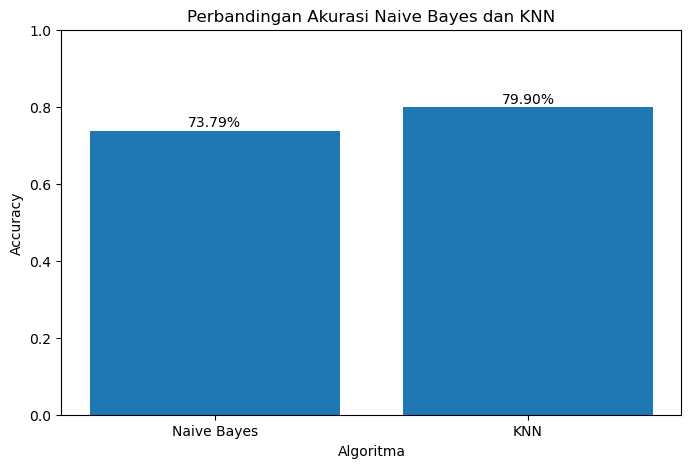

In [7]:
# Mengambil nilai accuracy dari hasil evaluasi
akurasi = hasil_evaluasi['Accuracy']

# Membuat grafik perbandingan
plt.figure(figsize=(8, 5))

plt.bar(
    hasil_evaluasi['Model'],
    akurasi
)

plt.title('Perbandingan Akurasi Naive Bayes dan KNN')
plt.xlabel('Algoritma')
plt.ylabel('Accuracy')
plt.ylim(0, 1)

for i, nilai in enumerate(akurasi):
    plt.text(i, nilai + 0.01, f'{nilai:.2%}', ha='center')

plt.show()

# TAQIYA RIZKIPUDENTA_202431180

## 8. Confusion matrix

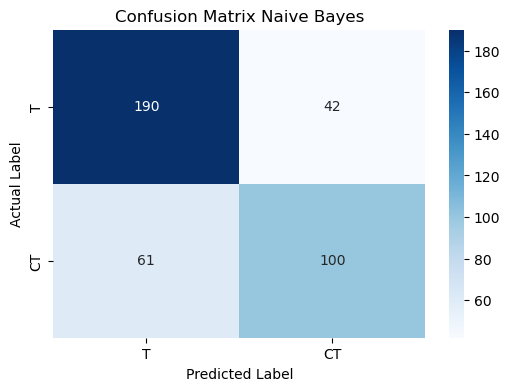

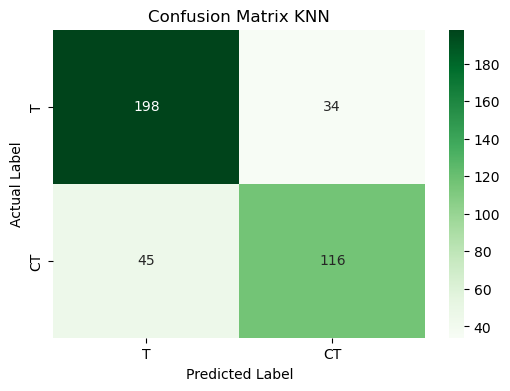

In [8]:
# Confusion Matrix Naive Bayes
cm_nb = confusion_matrix(
    y_test,
    y_pred_nb,
    labels=['T', 'CT']
)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_nb,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['T', 'CT'],
    yticklabels=['T', 'CT']
)

plt.title('Confusion Matrix Naive Bayes')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.show()


# Confusion Matrix KNN
cm_knn = confusion_matrix(
    y_test,
    y_pred_knn,
    labels=['T', 'CT']
)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_knn,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['T', 'CT'],
    yticklabels=['T', 'CT']
)

plt.title('Confusion Matrix KNN')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.show()

# TAQIYA RIZKIPUDENTA_202431180

## 9. Menampilkan hasil prediksi aktual dan model

In [9]:
# Membuat tabel hasil prediksi
hasil_prediksi = pd.DataFrame({
    'Aktual': y_test.values,
    'Prediksi Naive Bayes': y_pred_nb,
    'Prediksi KNN': y_pred_knn
})

# Menampilkan 20 data pertama
hasil_prediksi.head(20)

# TAQIYA RIZKIPUDENTA_202431180

,Aktual,Prediksi Naive Bayes,Prediksi KNN
0,CT,CT,CT
1,CT,T,CT
2,T,T,T
3,T,T,T
4,T,T,T
5,CT,T,CT
6,CT,CT,CT
7,T,CT,T
8,T,T,T
9,T,T,T
